In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00


In [ ]:
!pip install xgboost catboost scikit-learn seaborn matplotlib imbalanced-learn


In [ ]:
!pip install pmdarima==2.0.4 --no-cache-dir --quiet
!pip install lightgbm optuna tensorflow scikit-learn catboost xgboost joblib --no-cache-dir --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 10.8 MB/s eta 0:00:00


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000262 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1572
[LightGBM] [Info] Number of data points in the train set: 312, number of used features: 33
[LightGBM] [Info] Start training from score -5.049856
[LightGBM] [Info] Start training from score -2.375707
[LightGBM] [Info] Start training from score -1.452544
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.981803
[LightGBM] [Info] Start training from score -1.015615
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Wa

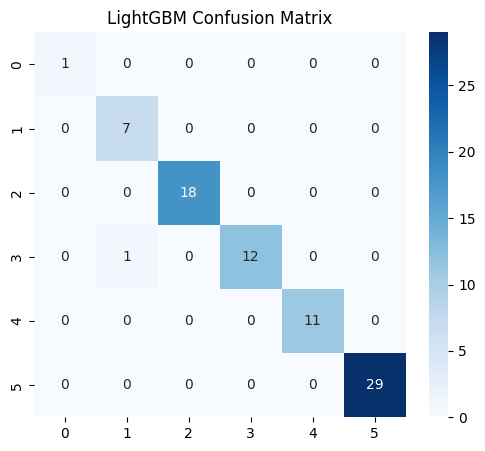

Random Forest → Acc=0.9620, F1=0.9666


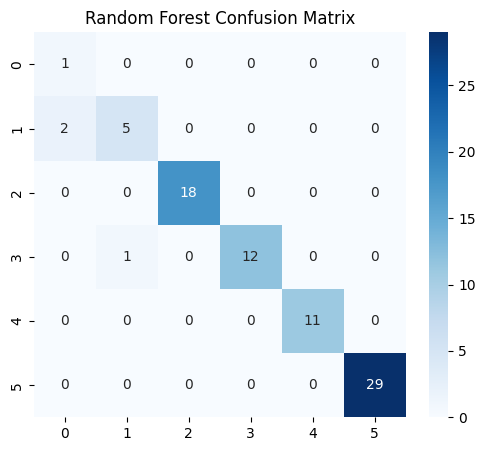

Decision Tree → Acc=0.9620, F1=0.9666


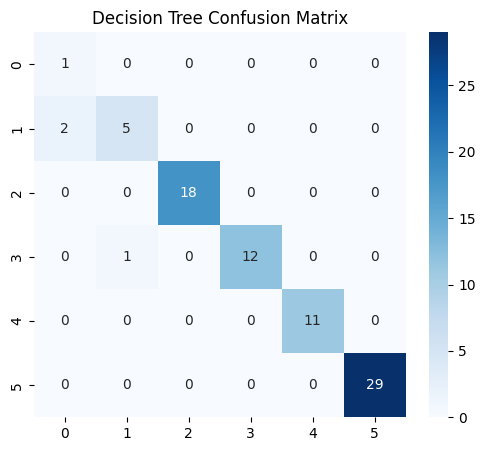

SVM → Acc=0.9747, F1=0.9687


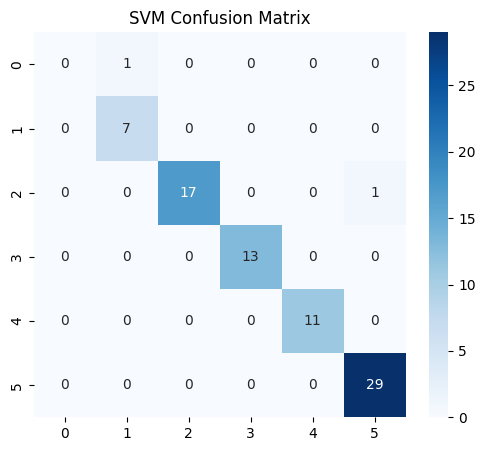

Weighted Classifier → Acc=0.9620, F1=0.9682


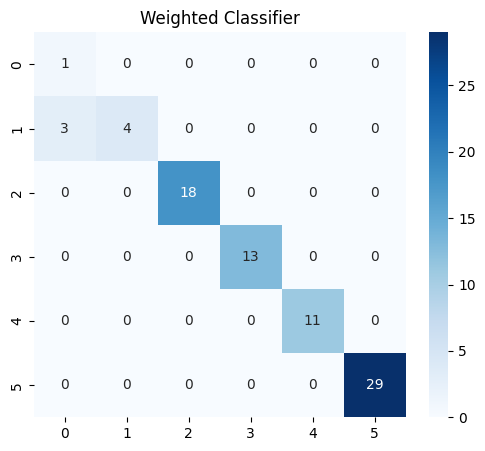

XGBoost (Tuned) → Acc=0.9747, F1=0.9697


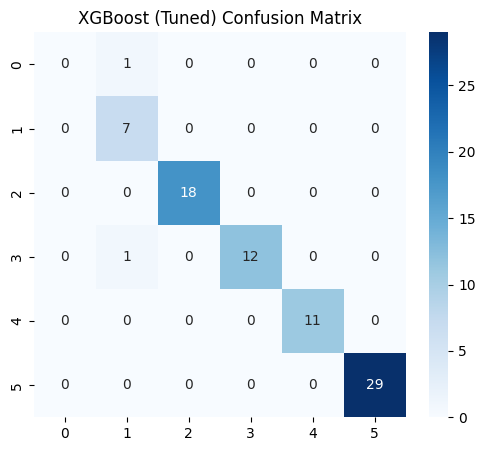

CatBoost (Tuned) → Acc=0.9747, F1=0.9697


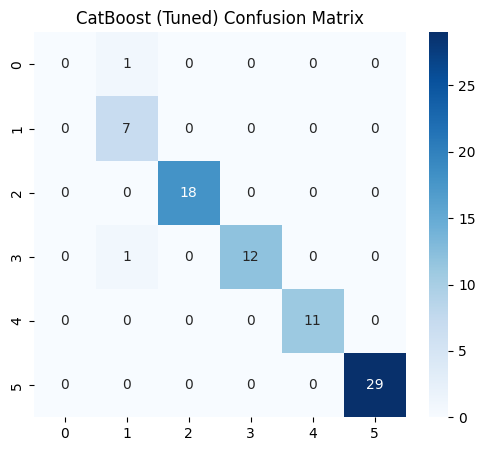

Stacking Ensemble → Acc=0.9747, F1=0.9765


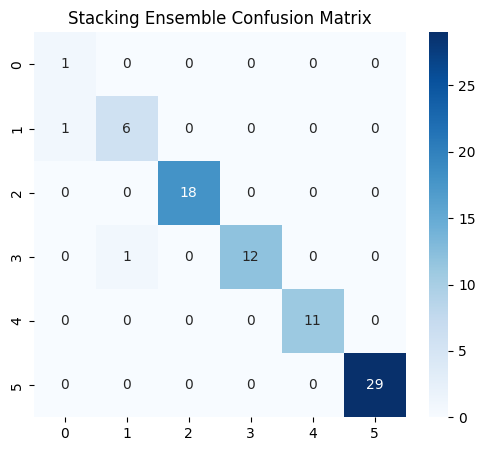

Linear Regression → R²=1.0000, RMSE=0.0000


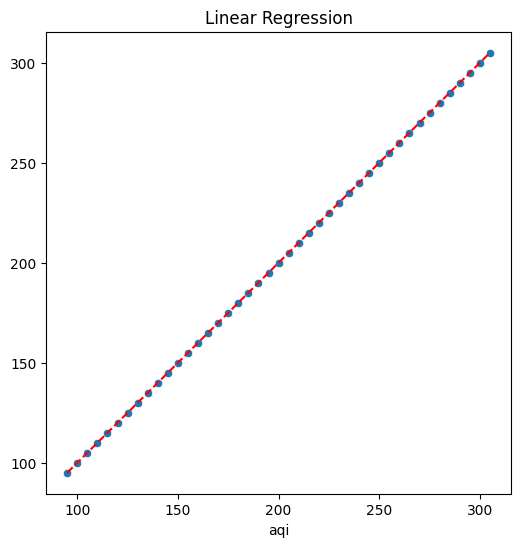

Random Forest → R²=0.9989, RMSE=1.8209


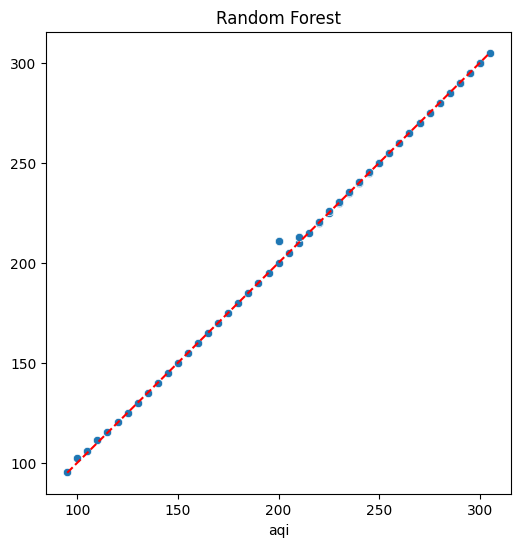

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001396 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 313, number of used features: 33
[LightGBM] [Info] Start training from score 202.683706
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

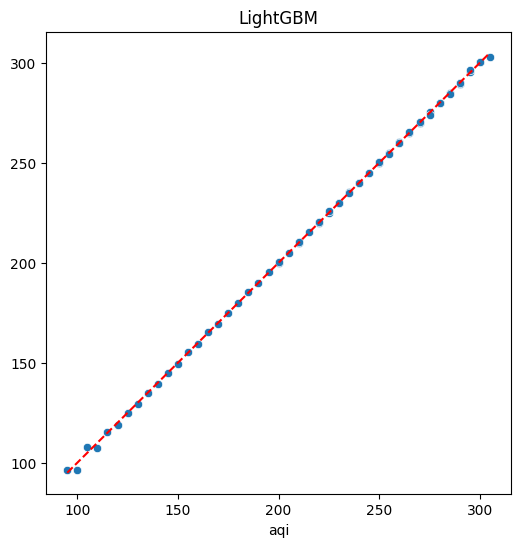

XGBoost → R²=1.0000, RMSE=0.0293


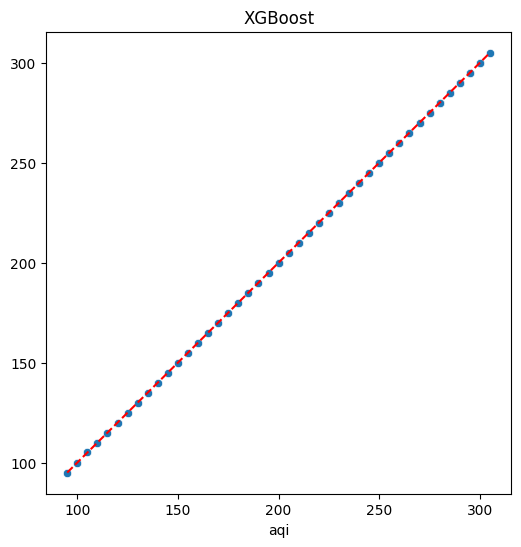

CatBoost → R²=0.9951, RMSE=3.9294


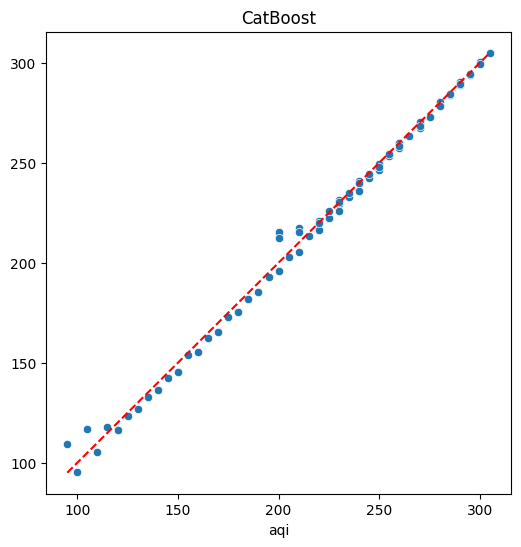

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
BP Neural Network → R²=0.9289


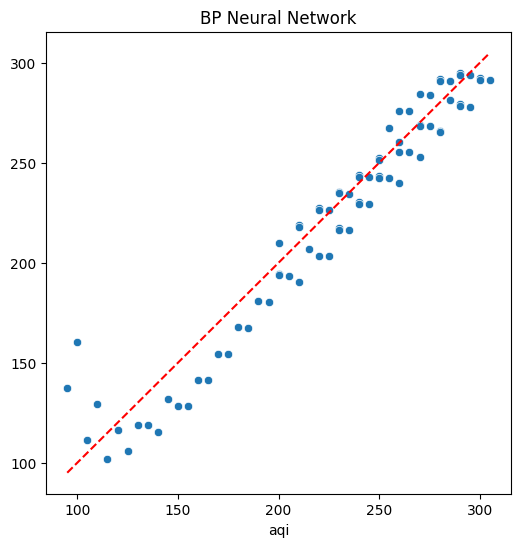

Stacking Ensemble → R²=1.0000, RMSE=0.1160


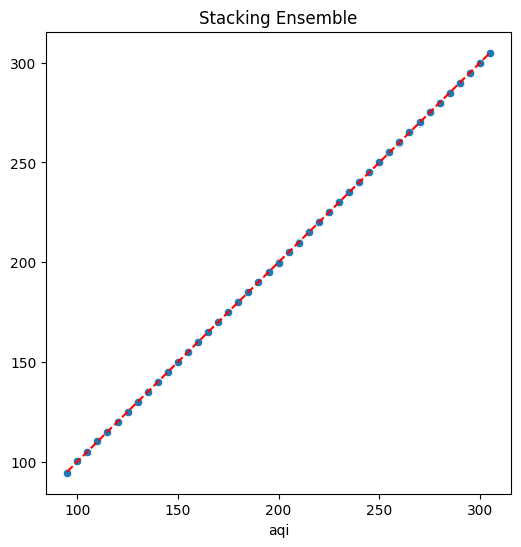


Pipeline Complete.


In [ ]:
# =====================================================
# Final AQI Prediction Pipeline (Minimal Comment Version)
# Classification: DT, RF, SVM, LightGBM, XGBoost, CatBoost, Weighted, Stacking
# Regression: Linear, RF, LightGBM, XGBoost, CatBoost, BP-NN, Stacking
# Removed: Logistic Regression (classification), LSTM, ARIMA, Weighted Regression
# Plots Enabled
# =====================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, StackingClassifier, StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, confusion_matrix,
    r2_score, mean_squared_error, mean_absolute_error
)

# Optional models
HAS_XGBOOST = True
HAS_CATBOOST = True
HAS_LIGHTGBM = True
HAS_TF = True

try:
    from xgboost import XGBClassifier, XGBRegressor
except:
    HAS_XGBOOST = False

try:
    from catboost import CatBoostClassifier, CatBoostRegressor
except:
    HAS_CATBOOST = False

try:
    from lightgbm import LGBMClassifier, LGBMRegressor
except:
    HAS_LIGHTGBM = False

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
except:
    HAS_TF = False

PLOT = True
FILE_PATH = "/content/dataset.csv"
RANDOM_STATE = 42

# --------------------------
# Load dataset
# --------------------------
cols = ['date', 'aqi', 'class', 'pm2.5', 'pm10', 'so2', 'co', 'no2', 'o3']
df = pd.read_csv(FILE_PATH, on_bad_lines="skip", names=cols, header=0)

df['date'] = pd.to_datetime(df['date'], format='%Y%m%d', errors='coerce')
df = df.dropna(subset=['date']).reset_index(drop=True)

translation_map = {
    "优": "Excellent", "良": "Good",
    "轻度污染": "Lightly Polluted", "中度污染": "Moderately Polluted",
    "重度污染": "Heavily Polluted", "严重污染": "Severely Polluted"
}
df['class'] = df['class'].map(lambda x: translation_map.get(x, x))

df = df.dropna().reset_index(drop=True)

# --------------------------
# Feature Engineering
# --------------------------
df['month'] = df['date'].dt.month
df['dayofyear'] = df['date'].dt.dayofyear
df['weekday'] = df['date'].dt.weekday

pollutants = ['pm2.5', 'pm10', 'so2', 'co', 'no2', 'o3']
for p in pollutants:
    for lag in [1, 2, 3]:
        df[f'{p}_lag{lag}'] = df[p].shift(lag)
    df[f'{p}_roll3'] = df[p].rolling(window=3, min_periods=1).mean()

df = df.dropna().reset_index(drop=True)

# ============================================================
# CLASSIFICATION
# ============================================================
X_cls = df.drop(columns=['date', 'aqi', 'class'])
y_cls = df['class'].astype(str)

le = LabelEncoder()
y_cls_enc = le.fit_transform(y_cls)

class_counts = pd.Series(y_cls_enc).value_counts()
rare = class_counts[class_counts < 2].index.tolist()
if len(rare) > 0:
    mask = ~pd.Series(y_cls_enc).isin(rare)
    X_cls = X_cls[mask]
    y_cls_enc = y_cls_enc[mask]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls_enc, test_size=0.2, stratify=y_cls_enc, random_state=RANDOM_STATE
)

scaler_cls = MinMaxScaler()
X_train_c = scaler_cls.fit_transform(X_train_c)
X_test_c = scaler_cls.transform(X_test_c)

models_cls = []

if HAS_LIGHTGBM:
    models_cls.append((LGBMClassifier(random_state=RANDOM_STATE), "LightGBM"))

models_cls.append((RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), "Random Forest"))
models_cls.append((DecisionTreeClassifier(random_state=RANDOM_STATE), "Decision Tree"))
models_cls.append((SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE), "SVM"))

classification_results = []
fitted_class_models = {}

def eval_cls(model, name):
    model.fit(X_train_c, y_train_c)
    y_pred = model.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    f1 = f1_score(y_test_c, y_pred, average='weighted')
    print(f"{name} → Acc={acc:.4f}, F1={f1:.4f}")
    if PLOT:
        cm = confusion_matrix(y_test_c, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f"{name} Confusion Matrix")
        plt.show()
    return acc, f1, model

# Base models
for model, name in models_cls:
    try:
        acc, f1, fitted = eval_cls(model, name)
        classification_results.append([name, acc, f1])
        fitted_class_models[name] = fitted
    except Exception as e:
        print("Failed:", name, e)

# Weighted Classifier (keep)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf.fit(X_train_c, y_train_c)
log = SVC(probability=True)  # logistic excluded → using SVC as second source
log.fit(X_train_c, y_train_c)
pred_rf = rf.predict_proba(X_test_c)
pred_log = log.predict_proba(X_test_c)
final_pred = np.argmax((pred_rf + pred_log) / 2, axis=1)
acc = accuracy_score(y_test_c, final_pred)
f1 = f1_score(y_test_c, final_pred, average='weighted')
classification_results.append(["Weighted Classifier", acc, f1])
print(f"Weighted Classifier → Acc={acc:.4f}, F1={f1:.4f}")

if PLOT:
    cm = confusion_matrix(y_test_c, final_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Weighted Classifier")
    plt.show()

# Tuned XGBoost / CatBoost + Stacking
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stack_estimators = []

if HAS_XGBOOST:
    xgb = XGBClassifier(eval_metric='mlogloss', random_state=RANDOM_STATE)
    params = {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}
    gs_xgb = GridSearchCV(xgb, params, scoring="f1_weighted", cv=cv_cls, n_jobs=-1)
    gs_xgb.fit(X_train_c, y_train_c)
    xgb_best = gs_xgb.best_estimator_
    acc, f1, _ = eval_cls(xgb_best, "XGBoost (Tuned)")
    classification_results.append(["XGBoost (Tuned)", acc, f1])
    stack_estimators.append(("xgb", xgb_best))

if HAS_CATBOOST:
    cat = CatBoostClassifier(verbose=False, random_state=RANDOM_STATE)
    params = {"iterations": [100, 200], "learning_rate": [0.05, 0.1], "depth": [4, 6]}
    gs_cat = GridSearchCV(cat, params, scoring="f1_weighted", cv=cv_cls, n_jobs=-1)
    gs_cat.fit(X_train_c, y_train_c)
    cat_best = gs_cat.best_estimator_
    acc, f1, _ = eval_cls(cat_best, "CatBoost (Tuned)")
    classification_results.append(["CatBoost (Tuned)", acc, f1])
    stack_estimators.append(("cat", cat_best))

# Stacking (keep)
stack_cls = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=RandomForestClassifier(),
    n_jobs=-1
)
acc, f1, _ = eval_cls(stack_cls, "Stacking Ensemble")
classification_results.append(["Stacking Ensemble", acc, f1])

# Save summary
cls_df = pd.DataFrame(classification_results, columns=["Model", "Accuracy", "F1"])
cls_df.to_csv("classification_summary.csv", index=False)

# ============================================================
# REGRESSION
# ============================================================
df = df.set_index('date').sort_index()
X_reg = df.drop(columns=['class', 'aqi'])
y_reg = df['aqi']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, shuffle=False, random_state=RANDOM_STATE
)

scaler_r = MinMaxScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

def eval_reg(model, name):
    model.fit(X_train_r, y_train_r)
    pred = model.predict(X_test_r)
    r2 = r2_score(y_test_r, pred)
    rmse = mean_squared_error(y_test_r, pred)**0.5
    mae = mean_absolute_error(y_test_r, pred)
    print(f"{name} → R²={r2:.4f}, RMSE={rmse:.4f}")
    if PLOT:
        plt.figure(figsize=(6,6))
        sns.scatterplot(x=y_test_r, y=pred)
        plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], "r--")
        plt.title(name)
        plt.show()
    return pred, r2

results_reg = {}

# Base regressors
base_regressors = []

base_regressors.append((LinearRegression(), "Linear Regression"))
base_regressors.append((RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), "Random Forest"))

if HAS_LIGHTGBM:
    base_regressors.append((LGBMRegressor(random_state=RANDOM_STATE), "LightGBM"))

if HAS_XGBOOST:
    base_regressors.append((XGBRegressor(random_state=RANDOM_STATE), "XGBoost"))

if HAS_CATBOOST:
    base_regressors.append((CatBoostRegressor(verbose=False, random_state=RANDOM_STATE), "CatBoost"))

# Run regression models
for model, name in base_regressors:
    pred, r2 = eval_reg(model, name)
    results_reg[name] = (pred, r2)

# BP Neural Network (keep)
if HAS_TF:
    tf.keras.backend.clear_session()
    nn = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(X_train_r.shape[1],)),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)
    ])
    nn.compile(optimizer='adam', loss='mse')
    nn.fit(X_train_r, y_train_r, epochs=30, batch_size=16, verbose=0)
    pred_nn = nn.predict(X_test_r).flatten()
    r2_nn = r2_score(y_test_r, pred_nn)
    print(f"BP Neural Network → R²={r2_nn:.4f}")
    if PLOT:
        plt.figure(figsize=(6,6))
        sns.scatterplot(x=y_test_r, y=pred_nn)
        plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], "r--")
        plt.title("BP Neural Network")
        plt.show()
    results_reg["BP Neural Network"] = (pred_nn, r2_nn)

# Stacking Regressor (keep)
stack_reg_estimators = []

if HAS_XGBOOST:
    stack_reg_estimators.append(("xgb", XGBRegressor(random_state=RANDOM_STATE)))
if HAS_CATBOOST:
    stack_reg_estimators.append(("cat", CatBoostRegressor(verbose=False, random_state=RANDOM_STATE)))

stack_reg = StackingRegressor(
    estimators=stack_reg_estimators,
    final_estimator=LinearRegression(),
    n_jobs=-1
)

pred_st, r2_st = eval_reg(stack_reg, "Stacking Ensemble")
results_reg["Stacking Ensemble"] = (pred_st, r2_st)

# Save regression summary
df_reg = pd.DataFrame([(m, float(r2)) for m, (_, r2) in results_reg.items()], columns=["Model", "R²"])
df_reg.to_csv("regression_summary.csv", index=False)

print("\nPipeline Complete.")
